In [ ]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Point to the folder where your kaggle.json is stored
# (Adjust "kaggle_data" to your specific folder name if different)
os.environ['KAGGLE_CONFIG_DIR'] = "/content/drive/MyDrive/kaggle_data"

# 3. Create and switch to your target destination folder in Drive
# This avoids the "No such file or directory" error
TARGET_DIR = "/content/drive/MyDrive/chest_xray"
os.makedirs(TARGET_DIR, exist_ok=True)
%cd {TARGET_DIR}

# 4. Upgrade Kaggle CLI to resolve the version warning
!pip install --upgrade kaggle

# 5. Re-download the dataset directly to this Drive folder
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

# 6. Unzip the file safely
!unzip -q chest-xray-pneumonia.zip


Mounted at /content/drive
/content/drive/MyDrive/chest_xray
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.6 MB/s eta 0:00:00
  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:22<00:00, 109MB/s]



In [1]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/chest_xray/chest-xray-pneumonia.zip" -d "/content/extracted_data"


Mounted at /content/drive


In [2]:
import os
from pathlib import Path

# Define the base directory for the extracted dataset
data_dir = Path('/content/extracted_data/chest_xray/chest_xray')

# Let's inspect the subdirectories inside the dataset
for split in ['train', 'val', 'test']:
    split_dir = data_dir / split
    if split_dir.exists():
        subdirs = [d.name for d in split_dir.iterdir() if d.is_dir()]
        print(f"{split.capitalize()} split directory contains: {subdirs}")

Train split directory contains: ['PNEUMONIA', 'NORMAL']
Val split directory contains: ['PNEUMONIA', 'NORMAL']
Test split directory contains: ['PNEUMONIA', 'NORMAL']


Number of NORMAL training images: 1341
Number of PNEUMONIA training images: 3875


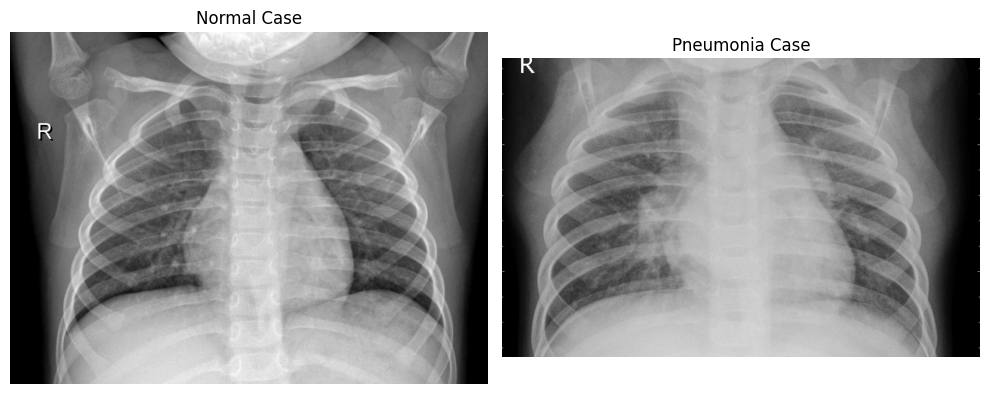

In [3]:
from PIL import Image
import matplotlib.pyplot as plt

# Let's count the images in the training folders
train_normal_dir = data_dir / 'train' / 'NORMAL'
train_pneumonia_dir = data_dir / 'train' / 'PNEUMONIA'

normal_images = list(train_normal_dir.glob('*.jpeg'))
pneumonia_images = list(train_pneumonia_dir.glob('*.jpeg'))

print(f"Number of NORMAL training images: {len(normal_images)}")
print(f"Number of PNEUMONIA training images: {len(pneumonia_images)}")

# Display the first image from each category
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

if normal_images:
    img_normal = Image.open(normal_images[0])
    axes[0].imshow(img_normal, cmap='gray')
    axes[0].set_title("Normal Case")
    axes[0].axis('off')

if pneumonia_images:
    img_pneumonia = Image.open(pneumonia_images[0])
    axes[1].imshow(img_pneumonia, cmap='gray')
    axes[1].set_title("Pneumonia Case")
    axes[1].axis('off')

plt.tight_layout()
plt.show()

### 1. Build Training, Validation, and Test Pipelines
We will use `image_dataset_from_directory` to load our dataset dynamically. This handles converting the raw JPEGs into model-ready tensor batches, resizing them, and applying proper categorization.

In [4]:
import tensorflow as tf

# Define constants
BATCH_SIZE = 32
IMG_SIZE = (224, 224) # Standard input size for many CNN backbones

train_dir = data_dir / 'train'
val_dir = data_dir / 'val'
test_dir = data_dir / 'test'

# Load datasets as tf.data.Dataset objects
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels='inferred',
    label_mode='binary', # Use binary classification since we have Normal vs Pneumonia
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    labels='inferred',
    label_mode='binary',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels='inferred',
    label_mode='binary',
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


### 2. Configure Performance & Normalization
We can configure buffering and caching strategies on our datasets so that fetching batches from disk does not bottleneck the GPU or CPU training pipeline.

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

# Shuffle, cache and prefetch datasets
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Set up a normalization layer to scale pixel values from [0, 255] to [0, 1] during model execution
normalization_layer = tf.keras.layers.Rescaling(1./255)

print("Datasets successfully optimized and ready for training.")

Datasets successfully optimized and ready for training.


### 3. Build and Compile the CNN Model
We will define a Convolutional Neural Network (CNN) architecture. Since we are classifying images into two classes (Normal vs Pneumonia), we will use a sigmoid activation in the final layer and binary cross-entropy loss.

In [6]:
from tensorflow.keras import layers, models

# Define the architecture
model = models.Sequential([
    # Apply the normalization layer we created earlier
    normalization_layer,

    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten the results to feed into a Dense Layer
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Add dropout to prevent overfitting

    # Output layer for binary classification
    layers.Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

# Build the model by passing dummy data to see the summary
model.build(input_shape=(None, 224, 224, 3))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### 4. Train the Model
We will now train the CNN model using the `fit` method. To optimize training efficiency and avoid overfitting, we'll implement an `EarlyStopping` callback that monitors our validation loss.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping

# Define early stopping to restore the best weights when validation loss stops improving
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train the model
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 57s 66ms/step - accuracy: 0.8865 - loss: 0.2759 - precision: 0.9070 - recall: 0.9440 - val_accuracy: 0.5625 - val_loss: 0.7928 - val_precision: 0.5333 - val_recall: 1.0000
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - accuracy: 0.9509 - loss: 0.1297 - precision: 0.9646 - recall: 0.9695 - val_accuracy: 0.8750 - val_loss: 0.2394 - val_precision: 1.0000 - val_recall: 0.7500
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.9651 - loss: 0.0988 - precision: 0.9773 - recall: 0.9757 - val_accuracy: 0.8125 - val_loss: 0.3523 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.9737 - loss: 0.0741 - precision: 0.9817 - recall: 0.9830 - val_accuracy: 0.8750 - val_loss: 0.2458 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.9739 - loss: 0.0736 - precision: 0.9815 - recall: 0.9835 - val_accuracy: 0.8750 - val_lo

### 5. Visualize Training History
After training, it is helpful to plot the loss and accuracy curves for both training and validation sets to inspect how well the model has learned.

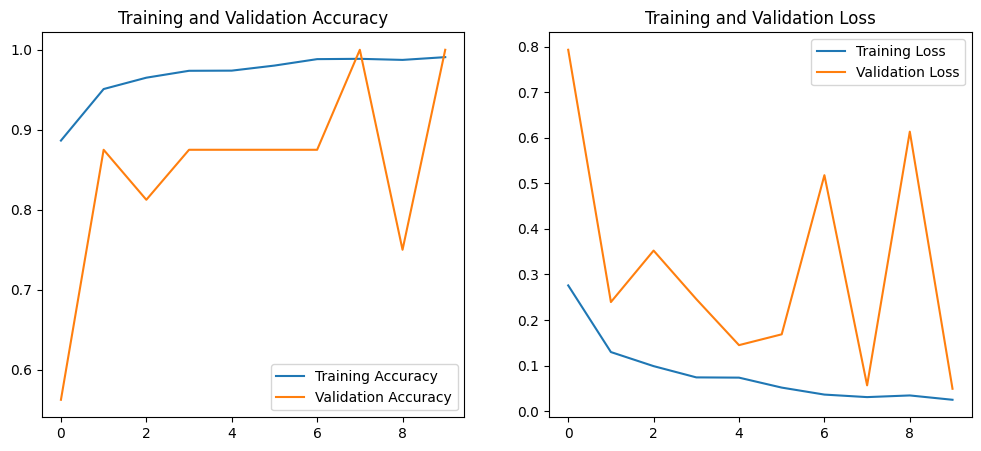

In [8]:
import matplotlib.pyplot as plt

# Extract metrics from history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

# Plot accuracy and loss curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()

### 6. Evaluate on the Test Dataset
Now, we evaluate the trained model on our held-out test dataset to obtain unbiased metrics of its performance.

In [9]:
# Evaluate the model on the test dataset
test_results = model.evaluate(test_ds)

# Map metrics to their respective results
for metric_name, value in zip(model.metrics_names, test_results):
    print(f"Test {metric_name.capitalize()}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.7484 - loss: 1.5251 - precision: 0.7178 - recall: 0.9846
Test Loss: 1.5251
Test Compile_metrics: 0.7484


### 7. Detailed Evaluation: Confusion Matrix and Classification Report
To get a deeper understanding of the types of errors our model is making (False Positives vs False Negatives), we will extract predictions from the test set and plot a confusion matrix alongside a classification report.

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.93      0.35      0.51       234
   PNEUMONIA       0.72      0.98      0.83       390

    accuracy                           0.75       624
   macro avg       0.83      0.67      0.67       624
weighted avg       0.80      0.75      0.71       624



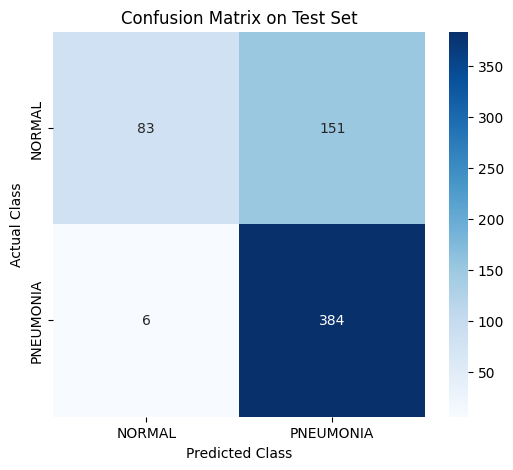

In [12]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Retrieve true labels and predicted probabilities
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    y_true.extend(labels.numpy())
    preds = model.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
# Apply threshold of 0.5 to get binary predictions
y_pred = (y_pred_probs > 0.5).astype(int)

# Explicitly set class names since the prefetched dataset loses the attribute
class_names = ['NORMAL', 'PNEUMONIA']

# Generate classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Generate and plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix on Test Set')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

### 8. Addressing Class Imbalance with Class Weights
To counter the extreme bias toward Pneumonia, we will calculate class weights based on our training dataset distribution and pass them to the `.fit()` method during retraining.

In [13]:
import numpy as np

# Count training images
num_normal = len(normal_images)
num_pneumonia = len(pneumonia_images)
total = num_normal + num_pneumonia

# Calculate class weights (inverse frequency scaling)
# Class 0: NORMAL, Class 1: PNEUMONIA
weight_for_0 = (1 / num_normal) * (total / 2.0)
weight_for_1 = (1 / num_pneumonia) * (total / 2.0)

class_weight = {0: weight_for_0, 1: weight_for_1}

print(f"Weight for Normal (Class 0): {weight_for_0:.2f}")
print(f"Weight for Pneumonia (Class 1): {weight_for_1:.2f}")

Weight for Normal (Class 0): 1.94
Weight for Pneumonia (Class 1): 0.67


### 9. Re-compile and Retrain the Model with Class Weights
Let's instantiate a fresh model, compile it, and train it using the calculated class weights to guide the optimizer.

In [14]:
# Recreate the same model architecture to start training from scratch
weighted_model = models.Sequential([
    normalization_layer,
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

# Compile the new model
weighted_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

# Retrain the model with class weights enabled
weighted_history = weighted_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    class_weight=class_weight
)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


163/163 ━━━━━━━━━━━━━━━━━━━━ 14s 60ms/step - accuracy: 0.8505 - loss: 0.3285 - precision: 0.9550 - recall: 0.8382 - val_accuracy: 0.8750 - val_loss: 0.3018 - val_precision: 0.8750 - val_recall: 0.8750
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.9431 - loss: 0.1483 - precision: 0.9812 - recall: 0.9414 - val_accuracy: 0.8125 - val_loss: 0.3158 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.9628 - loss: 0.1019 - precision: 0.9881 - recall: 0.9615 - val_accuracy: 0.8750 - val_loss: 0.2006 - val_precision: 1.0000 - val_recall: 0.7500


### 10. Re-Evaluate on the Test Set
Now we evaluate our newly trained balanced model and generate a new confusion matrix to compare the improvement.

Weighted Model Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.52      0.67       234
   PNEUMONIA       0.77      0.98      0.86       390

    accuracy                           0.81       624
   macro avg       0.85      0.75      0.76       624
weighted avg       0.83      0.81      0.79       624



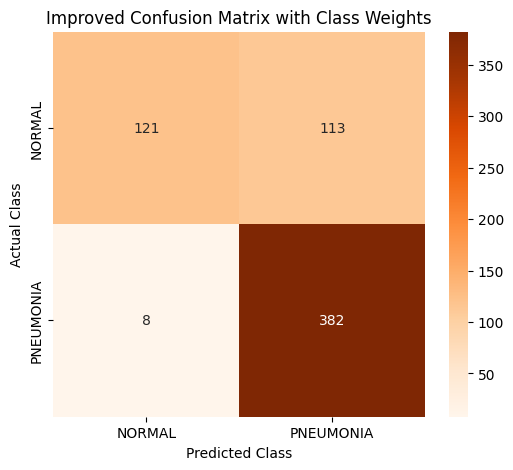

In [15]:
# Retrieve predictions from the balanced model
y_true_weighted = []
y_pred_probs_weighted = []

for images, labels in test_ds:
    y_true_weighted.extend(labels.numpy())
    preds = weighted_model.predict(images, verbose=0)
    y_pred_probs_weighted.extend(preds)

y_true_weighted = np.array(y_true_weighted)
y_pred_weighted = (np.array(y_pred_probs_weighted) > 0.5).astype(int)

# Display the improved classification report
print("Weighted Model Classification Report:")
print(classification_report(y_true_weighted, y_pred_weighted, target_names=class_names))

# Display the improved confusion matrix
cm_weighted = confusion_matrix(y_true_weighted, y_pred_weighted)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_weighted, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names)
plt.title('Improved Confusion Matrix with Class Weights')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

### 11. Save the Trained Model
We will now save our optimized, weighted model directly into our working directory on Google Drive.

In [16]:
model_save_path = 'pneumonia_classifier_weighted.keras'
weighted_model.save(model_save_path)
print(f"Model successfully saved to: {model_save_path}")

Model successfully saved to: pneumonia_classifier_weighted.keras
